# 1. Quick start

HERACLES reconstructs a cell lineage tree from a CRISPR lineage-tracing
character matrix. It places every cell as a point in hyperbolic space, moves
the points until the distances between them explain the observed edits under
a model of how the recorder works, and then builds a tree from those
distances with neighbour joining.

This notebook fits HERACLES to a simulated dataset of 250 cells and 30
target sites with missing data, and compares the result with the true tree
and with plain neighbour joining. It takes about five minutes on a laptop
CPU.

In [1]:
import logging
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from heracles import Heracles, robinson_foulds, sokal_collapse

# HERACLES logs every fit to stderr and to heracles.log in the output folder.
# Keep only warnings here so the notebook stays readable.
logging.getLogger("heracles").setLevel(logging.WARNING)
warnings.formatwarning = lambda message, category, *args, **kwargs: f"{category.__name__}: {message}\n"

DATA = Path("data")
RUNS = Path("runs")
RUNS.mkdir(exist_ok=True)

`rf_to_truth` collapses a tree and the true tree the same way and returns
their Robinson-Foulds distance.

In [2]:
def rf_to_truth(tree, cm, truth_path):
    """RF distance (count, normalised) to the true tree, both Camin-Sokal collapsed."""
    truth = sokal_collapse(Path(truth_path).read_text(), cm)
    tree = sokal_collapse(tree, cm)
    return robinson_foulds(tree, truth), robinson_foulds(tree, truth, normalized=True)

## Load a character matrix

One row per cell and one column per target site. Values are integer allele
ids: `0` is unedited, a positive id is an edit, and `-1` marks a missing
entry. The first column of the CSV holds the cell names.

In [3]:
cm = pd.read_csv(DATA / "cas9_mixed_dropout" / "characters.csv", index_col=0)
print(f"{cm.shape[0]} cells x {cm.shape[1]} sites, {(cm == -1).to_numpy().mean():.0%} missing")
cm.iloc[:5, :12]

250 cells x 30 sites, 22% missing


,site1,site2,site3,site4,site5,site6,site7,site8,site9,site10,site11,site12
cell,,,,,,,,,,,,
cell001,3,0,1,1,-1,2,-1,0,0,7,0,0
cell002,3,2,1,-1,11,0,24,0,0,4,0,0
cell003,0,-1,-1,0,65,0,0,10,0,-1,0,0
cell004,3,0,0,0,11,8,-1,-1,0,-1,0,-1
cell005,3,0,1,0,-1,15,-1,-1,0,-1,0,-1


## Fit

`Heracles(outdir=...)` with no other arguments runs the published method.
`fit()` accepts a DataFrame or a CSV path and writes its results to
`outdir`.

In [4]:
model = Heracles(outdir=RUNS / "quickstart", seed=0)
model.fit(cm)

print(f"iterations: {model.n_iter_}, converged: {model.converged_}")
print(f"embedding dimension: {model.dimension_}")

iterations: 4000, converged: True
embedding dimension: 80


If the fit stops at `max_iterations` (5000 by default) while the loss is
still going down, HERACLES warns and builds the trees from the final
embedding. The loss curve shows how close the fit was to flat. To fit
longer, raise `max_iterations`.

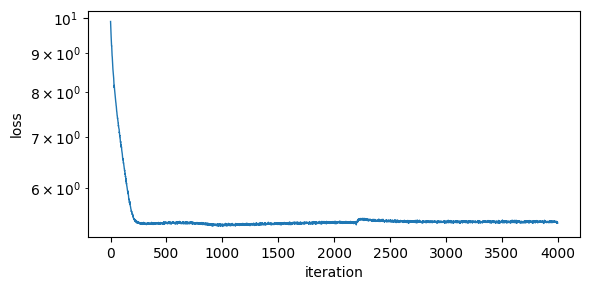

In [5]:
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(model.history_["loss"], lw=1)
ax.set_xlabel("iteration")
ax.set_ylabel("loss")
ax.set_yscale("log")
fig.tight_layout()

## The tree

`model.trees_` holds the reconstructed trees, rooted at a synthetic
unedited founder cell:

- `nj` is the fully binary neighbour-joining tree.
- `nj_collapsed` contracts every edge that carries no inferred edit
  (Camin-Sokal collapse). The data cannot resolve those edges, so this is
  the tree to use when comparing with another tree.

`model.newick(name)` returns a tree as a Newick string.

In [6]:
print(sorted(model.trees_))
print(model.newick("nj_collapsed")[:120], "...")

['nj', 'nj_collapsed']
[&R] ((((((cell195:0.12134,cell002:0.019149):0.20715,cell230:0.32876):0.31309,(((cell146:0.053958,cell071:0.33846):0.178 ...


## Compare with the true tree

The Robinson-Foulds (RF) distance counts the splits found in one tree but
not the other: 0 means the two trees are identical. The normalised RF
divides by the number of internal edges in both trees, so it runs from 0
(identical) to 1 (no split in common).

For a baseline, HERACLES keeps the tree it started from: RapidNJ
neighbour joining on the weighted Hamming distances between the cells'
character vectors, the usual distance-based method. It is in
`model.diagnostics_["init_tree_newick"]`.

In [7]:
truth_path = DATA / "cas9_mixed_dropout" / "true_tree.nwk"
rows = []
for name, tree in [("HERACLES", model.trees_["nj"]),
                   ("NJ (starting tree)", model.diagnostics_["init_tree_newick"])]:
    rf, nrf = rf_to_truth(tree, cm, truth_path)
    rows.append({"method": name, "RF": rf, "normalised RF": round(nrf, 3)})
pd.DataFrame(rows).set_index("method")

,RF,normalised RF
method,,
HERACLES,111,0.259
NJ (starting tree),161,0.384


## Embedding distances

`model.leaf_dists_` is the `(n, n)` matrix of distances between cells in
the fitted embedding, in the order of `model.labels_`. Ordering the cells by
their position in the tree shows the nested clades as blocks.

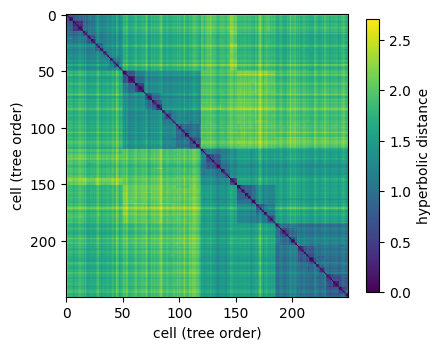

In [8]:
order = [leaf.taxon.label for leaf in model.trees_["nj"].leaf_nodes()]
index = [model.labels_.index(label) for label in order]
dists = model.leaf_dists_[np.ix_(index, index)]

fig, ax = plt.subplots(figsize=(4.5, 4))
im = ax.imshow(dists, cmap="viridis")
ax.set_xlabel("cell (tree order)")
ax.set_ylabel("cell (tree order)")
fig.colorbar(im, ax=ax, shrink=0.8, label="hyperbolic distance")
fig.tight_layout()

## Files, saving and loading

`fit()` writes the model, one Newick file per tree, the settings with the
fitted values (`config.json`) and the run log. `Heracles.load()` restores a
fitted model without refitting.

In [9]:
print(sorted(p.name for p in (RUNS / "quickstart").iterdir()))

restored = Heracles.load(RUNS / "quickstart" / "model.npz")
print(restored.newick("nj_collapsed") == model.newick("nj_collapsed"))

['config.json', 'heracles.log', 'model.npz', 'tree_nj.nwk', 'tree_nj_collapsed.nwk']
True


`model.write_report()` adds diagnostic plots and an HTML report to the same
folder.

## The same fit from the command line

```bash
heracles fit data/cas9_mixed_dropout/characters.csv --outdir runs/quickstart_cli --seed 0
heracles inspect runs/quickstart_cli/model.npz
```

`heracles fit --help` lists every option with its default.

**Next:** [2. Missing data](02_missing_data.ipynb).